# Retail Intelligence Platform

## Exploratory Data Analysis (EDA)

### Objectives
- Understand sales trends
- Analyze profit
- Identify top-performing products
- Analyze customer segments
- Explore regional performance
- Generate business insights

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Display all columns
pd.set_option("display.max_columns", None)

In [ ]:
df = pd.read_csv("../data/cleaned/cleaned_superstore.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Month Name,Order Quarter,Order Day,Order Weekday,Shipping Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,4,8,Tuesday,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,4,8,Tuesday,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,2,12,Sunday,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,4,11,Sunday,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,4,11,Sunday,7


In [ ]:
print("Total Sales : $", round(df["Sales"].sum(),2))
print("Total Profit : $", round(df["Profit"].sum(),2))
print("Total Orders :", df["Order ID"].nunique())
print("Total Customers :", df["Customer ID"].nunique())
print("Total Products :", df["Product Name"].nunique())

Total Sales : $ 2297200.86
Total Profit : $ 286397.02
Total Orders : 5009
Total Customers : 793
Total Products : 1850


In [ ]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values()

category_sales

Category
Office Supplies    719047.0320
Furniture          741999.7953
Technology         836154.0330
Name: Sales, dtype: float64

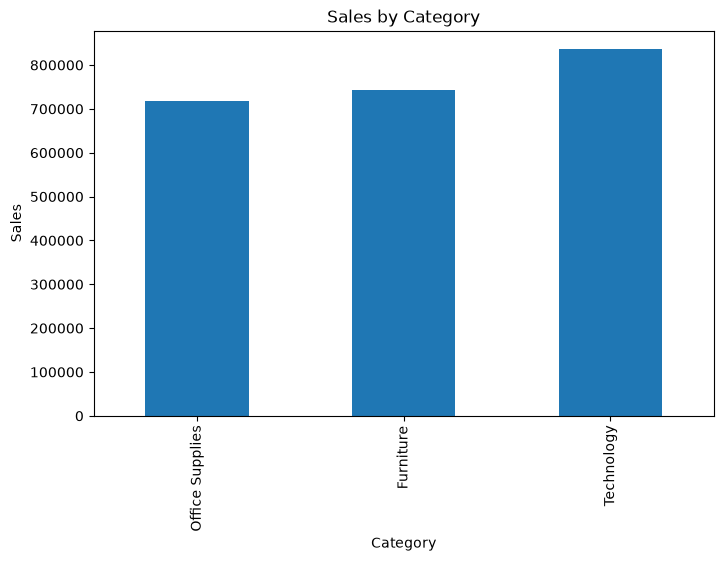

In [ ]:
category_sales.plot(
    kind="bar",
    figsize=(8,5),
    title="Sales by Category"
)

plt.xlabel("Category")
plt.ylabel("Sales")
plt.show()

In [ ]:
category_profit = df.groupby("Category")["Profit"].sum()

category_profit

Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64

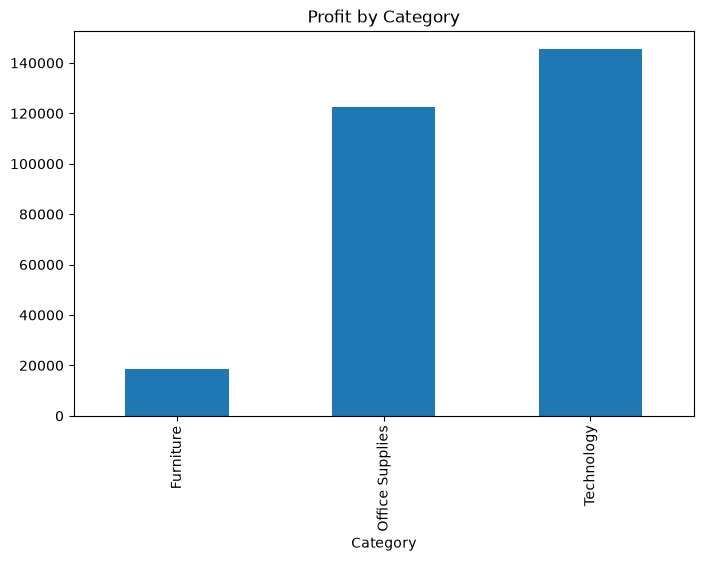

In [ ]:
category_profit.plot(
    kind="bar",
    figsize=(8,5),
    title="Profit by Category"
)

plt.show()

In [ ]:
region_sales = df.groupby("Region")["Sales"].sum()

region_sales

Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64

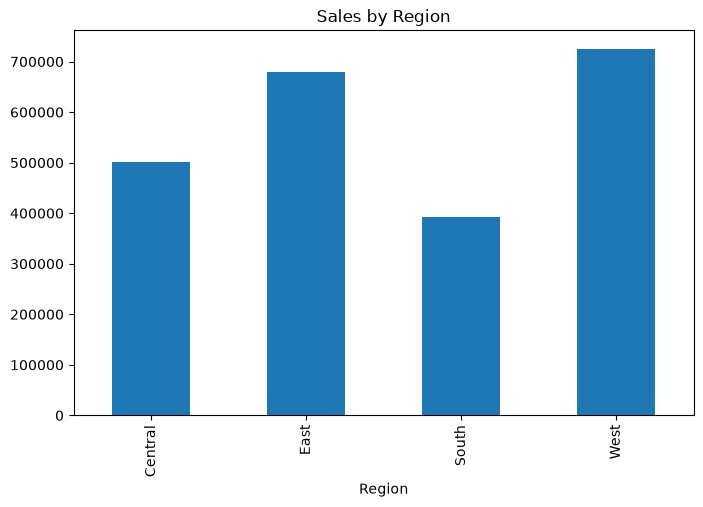

In [ ]:
region_sales.plot(
    kind="bar",
    figsize=(8,5),
    title="Sales by Region"
)

plt.show()

In [ ]:
region_profit = df.groupby("Region")["Profit"].sum()

region_profit

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64

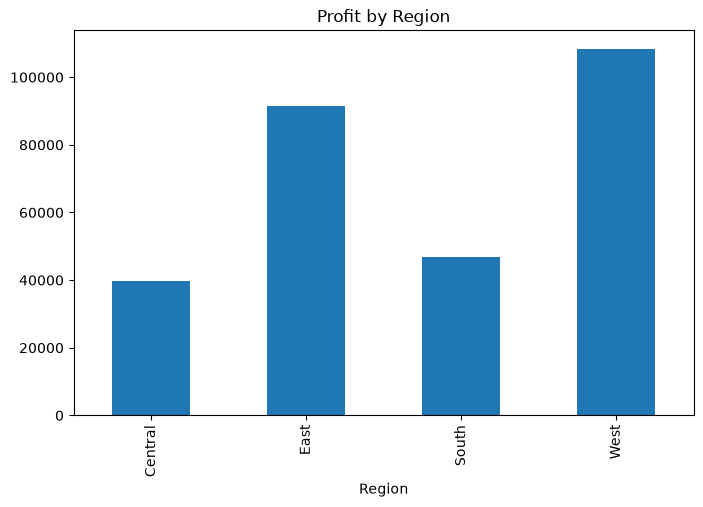

In [ ]:
region_profit.plot(
    kind="bar",
    figsize=(8,5),
    title="Profit by Region"
)

plt.show()

In [ ]:
monthly_sales = df.groupby("Order Month Name")["Sales"].sum()

monthly_sales

Order Month Name
April        137762.1286
August       159044.0630
December     325293.5035
February      59751.2514
January       94924.8356
July         147238.0970
June         152718.6793
March        205005.4888
May          155028.8117
November     352461.0710
October      200322.9847
September    307649.9457
Name: Sales, dtype: float64

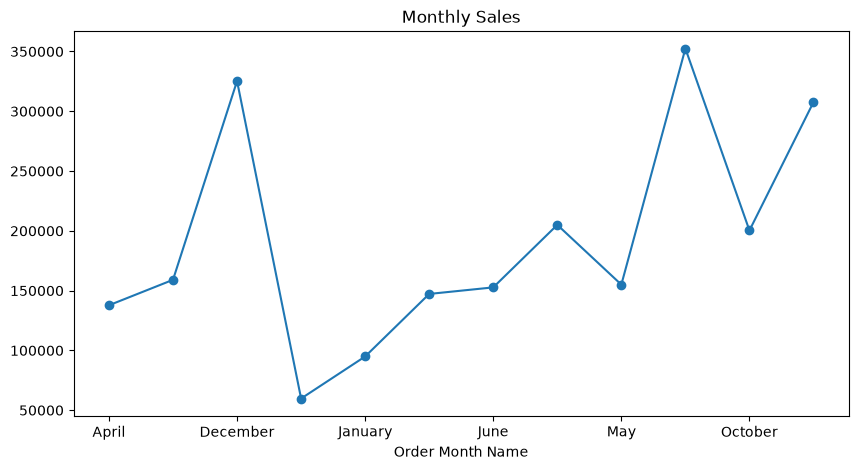

In [ ]:
monthly_sales.plot(
    kind="line",
    figsize=(10,5),
    marker="o",
    title="Monthly Sales"
)

plt.show()

In [ ]:
top_products = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

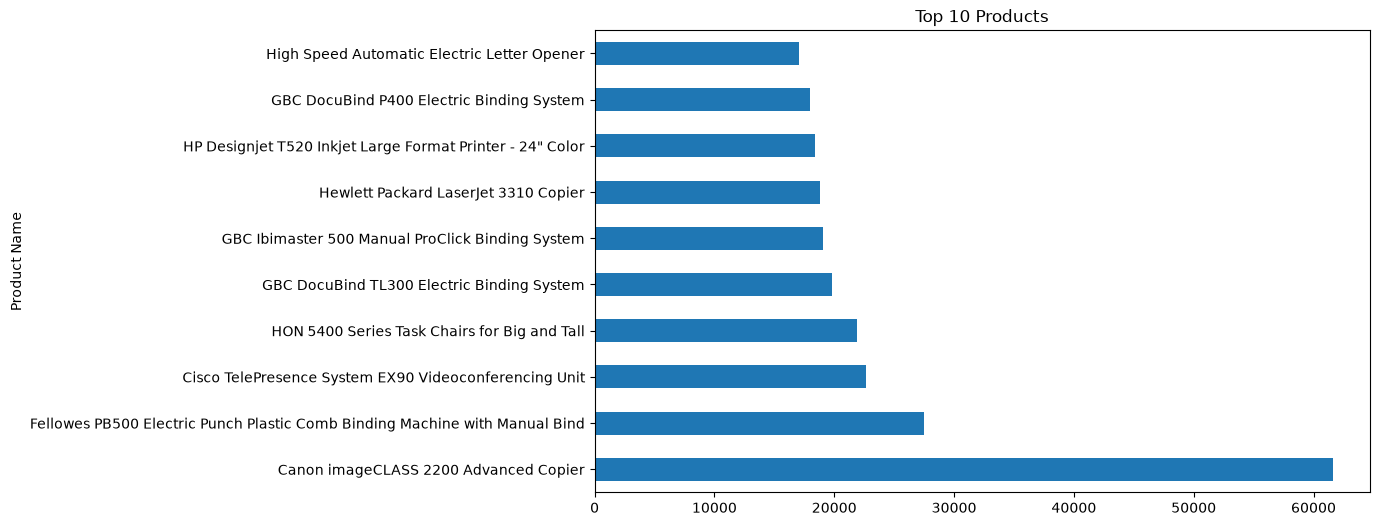

In [ ]:
top_products.plot(
    kind="barh",
    figsize=(10,6),
    title="Top 10 Products"
)

plt.show()

In [ ]:
top_customers = (
    df.groupby("Customer Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_customers

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

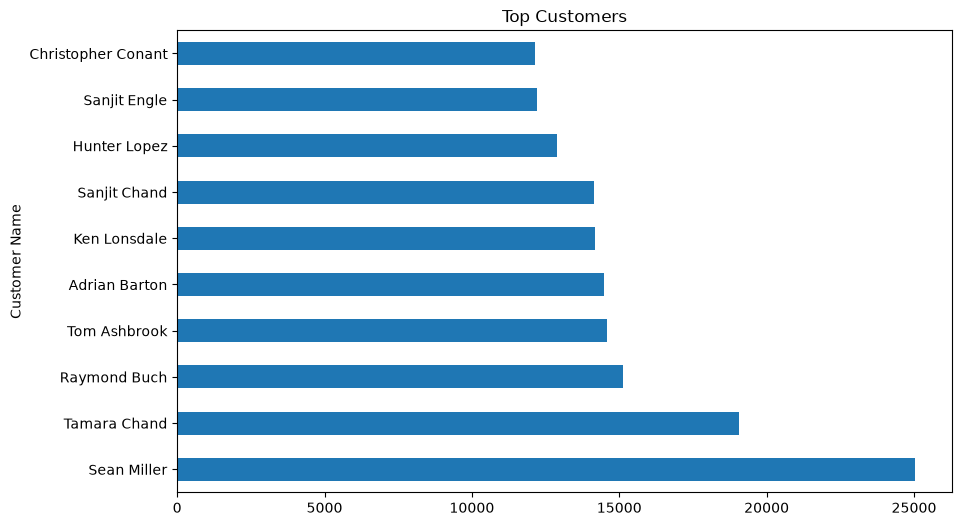

In [ ]:
top_customers.plot(
    kind="barh",
    figsize=(10,6),
    title="Top Customers"
)

plt.show()

In [ ]:
discount = df.groupby("Category")["Discount"].mean()

discount

Category
Furniture          0.173923
Office Supplies    0.157285
Technology         0.132323
Name: Discount, dtype: float64

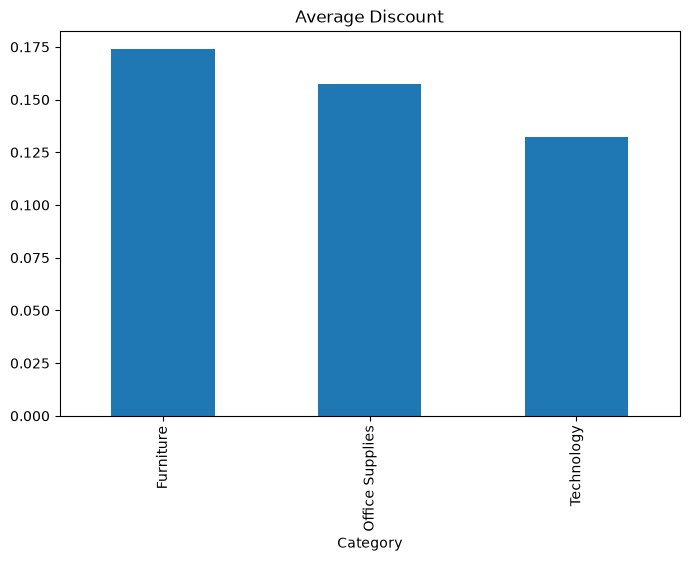

In [ ]:
discount.plot(
    kind="bar",
    figsize=(8,5),
    title="Average Discount"
)

plt.show()

In [ ]:
shipping = df.groupby("Ship Mode")["Shipping Days"].mean()

shipping

Ship Mode
First Class       2.182705
Same Day          0.044199
Second Class      3.238046
Standard Class    5.006535
Name: Shipping Days, dtype: float64

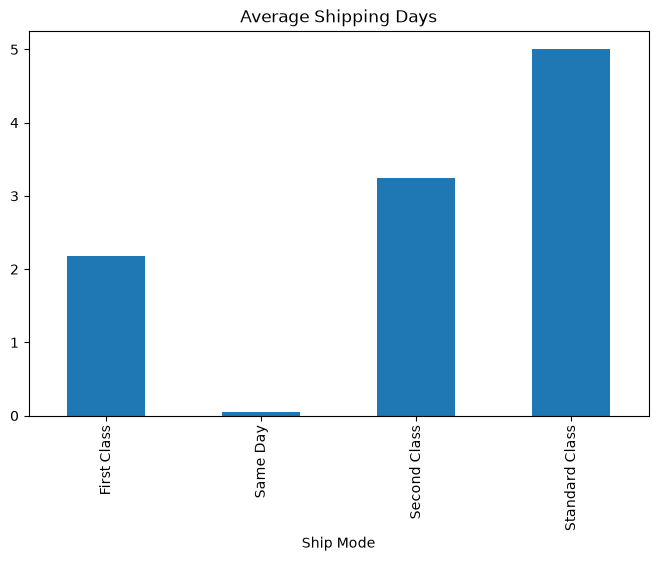

In [ ]:
shipping.plot(
    kind="bar",
    figsize=(8,5),
    title="Average Shipping Days"
)

plt.show()

In [ ]:
state_sales = (
    df.groupby("State")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

state_sales

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64

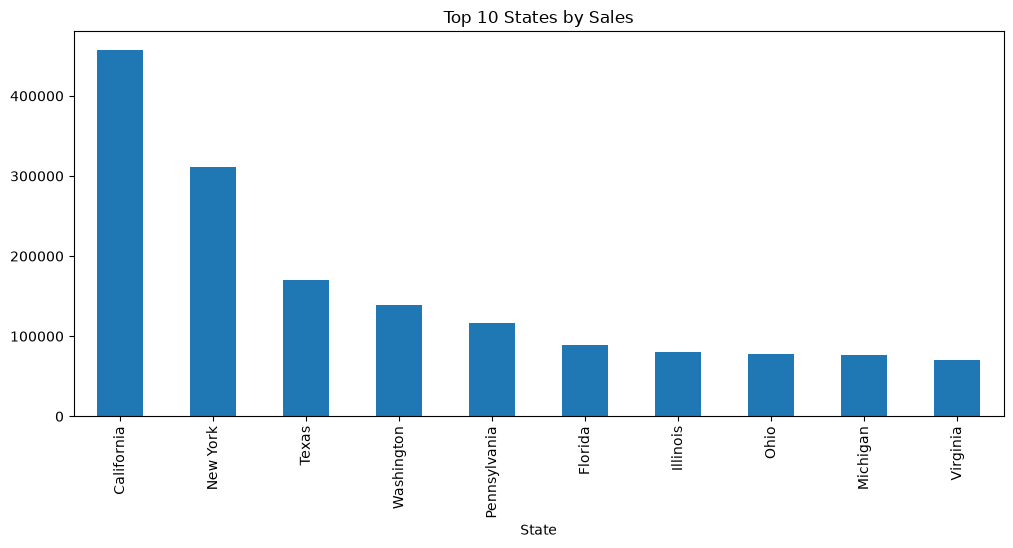

In [ ]:
state_sales.plot(
    kind="bar",
    figsize=(12,5),
    title="Top 10 States by Sales"
)

plt.show()

# Business Insights

- Identify the highest revenue category.
- Determine the most profitable region.
- Analyze which ship mode has the shortest delivery time.
- Find the top-performing products.
- Identify valuable customers.
- Understand the effect of discounts on profit.

In [ ]:
df.to_csv("../data/processed/processed_superstore.csv", index=False)

print("Processed dataset saved successfully.")

Processed dataset saved successfully.
